# 🚀 Practice Day 29

**📅 Date:** 2026-10-09  
📁 Category: Phase 1 · Pandas 기초 (Round 3/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Practice core Pandas fundamentals — filtering, sorting, groupby, and aggregation — on a simple single-table dataset
  (기본적인 Pandas 기초 — 필터링, 정렬, groupby, 집계 — 를 단순한 단일 테이블 데이터로 연습하기)
- Find the bakery's best sellers, which category earns the most, and how weekend traffic compares to weekdays
  (베이커리의 베스트셀러 상품, 가장 매출이 높은 카테고리, 주말과 평일 매출 차이를 파악하기)

---
# 📂 Dataset

**Dataset Name:** Millhouse Bakery — 일별 상품 판매 데이터 / Millhouse Bakery — Daily Product Sales

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 30 days (January 2024) of daily sales for 8 products across 4 categories (Bread, Pastries, Cakes, Beverages) — 240 rows total (8 products × 30 days), single table. Prices and revenue are in USD. Weekends see higher sales, and the data is clean — no missing values or duplicates.
(2024년 1월 한 달(30일) 동안 8개 상품(Bread/Pastries/Cakes/Beverages 4개 카테고리)의 일별 판매 데이터입니다(단일 테이블, 240행 = 8상품×30일, 가격·매출은 USD). 주말에는 판매량이 더 높으며, 결측치·중복 없이 깨끗합니다.)

## Dataset Preview

In [1]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
rng = np.random.default_rng(42)

# --- Generate a month of daily sales for 8 bakery products (prices in USD) ---
products = {
    'Sourdough Loaf': ('Bread', 5.50),
    'Baguette': ('Bread', 3.80),
    'Croissant': ('Pastries', 3.20),
    'Cinnamon Roll': ('Pastries', 3.50),
    'Danish': ('Pastries', 3.60),
    'Chocolate Cake Slice': ('Cakes', 6.20),
    'Carrot Cake Slice': ('Cakes', 5.80),
    'Latte': ('Beverages', 4.50),
}
base_qty = {
    'Sourdough Loaf': 18, 'Baguette': 22, 'Croissant': 35, 'Cinnamon Roll': 28,
    'Danish': 24, 'Chocolate Cake Slice': 14, 'Carrot Cake Slice': 11, 'Latte': 40
}

dates = pd.date_range('2024-01-01', periods=30, freq='D')

rows = []
for product, (category, price) in products.items():
    for d in dates:
        dow = d.dayofweek
        weekend_factor = 1.35 if dow in (5, 6) else 1.0
        noise = rng.normal(1.0, 0.15)
        qty = max(0, int(round(base_qty[product] * weekend_factor * noise)))
        revenue = round(qty * price, 2)
        rows.append({'date': d, 'product': product, 'category': category,
                     'quantity_sold': qty, 'revenue': revenue})

df = pd.DataFrame(rows).sort_values(['date', 'product']).reset_index(drop=True)

df.head(10)


,date,product,category,quantity_sold,revenue
0,2024-01-01,Baguette,Bread,29,110.2
1,2024-01-01,Carrot Cake Slice,Cakes,13,75.4
2,2024-01-01,Chocolate Cake Slice,Cakes,14,86.8
3,2024-01-01,Cinnamon Roll,Pastries,31,108.5
4,2024-01-01,Croissant,Pastries,26,83.2
5,2024-01-01,Danish,Pastries,20,72.0
6,2024-01-01,Latte,Beverages,45,202.5
7,2024-01-01,Sourdough Loaf,Bread,19,104.5
8,2024-01-02,Baguette,Bread,21,79.8
9,2024-01-02,Carrot Cake Slice,Cakes,11,63.8


## Dataset Information

In [2]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           240 non-null    datetime64[us]
 1   product        240 non-null    str           
 2   category       240 non-null    str           
 3   quantity_sold  240 non-null    int64         
 4   revenue        240 non-null    float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 9.5 KB

Shape: (240, 5)


,date,product,category,quantity_sold,revenue
count,240,240,240,240.000000,240.000000
unique,NaN,8,4,NaN,NaN
top,NaN,Baguette,Pastries,NaN,NaN
freq,NaN,30,90,NaN,NaN
mean,2024-01-15 12:00:00,NaN,NaN,26.016667,109.824167
min,2024-01-01 00:00:00,NaN,NaN,8.000000,46.400000
25%,2024-01-08 00:00:00,NaN,NaN,17.000000,82.175000
50%,2024-01-15 12:00:00,NaN,NaN,24.000000,99.200000
75%,2024-01-23 00:00:00,NaN,NaN,34.000000,124.800000
max,2024-01-30 00:00:00,NaN,NaN,62.000000,279.000000


---
# ❓ Business Questions

1. **(Analysis)** Which product sold the most units overall, and which sold the least?
   (전체 기간 기준 가장 많이/적게 팔린 상품은?)
2. **(Analysis)** Which category generated the most total revenue, and which the least?
   (가장 매출이 높은/낮은 카테고리는?)
3. **(Analysis)** How does average daily revenue compare between weekdays and weekends?
   (평일과 주말의 평균 일일 매출은 어떻게 다른가?)
4. **(Visualization)** Compare total units sold across all 8 products.
   (8개 상품의 총 판매량을 비교하면?)
5. **(Visualization)** Show how daily revenue moves across the month.
   (한 달간 일별 매출은 어떻게 변화하는가?)

---
# 🔍 Data Cleaning Check


In [3]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
date             0
product          0
category         0
quantity_sold    0
revenue          0
dtype: int64

Duplicate rows: 0

Dtypes
date             datetime64[us]
product                     str
category                    str
quantity_sold             int64
revenue                 float64
dtype: object

Column names
['date', 'product', 'category', 'quantity_sold', 'revenue']

Text columns — unique counts
product     8
category    4
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** Which product sold the most units overall, and which sold the least? (가장 많이/적게 팔린 상품은?)

**Result:** Latte **1,290**, Croissant **1,134**, Cinnamon Roll **881**, Danish **793**, Baguette **733**, Sourdough Loaf **593**, Chocolate Cake Slice **457**, Carrot Cake Slice **363**.

**Insight:** Latte sold **927** more units than Carrot Cake Slice. The top two are both high-volume items, Latte and Croissant.
(Latte가 Carrot Cake Slice보다 927개 더 팔림. 상위 둘은 판매량이 많은 Latte와 Croissant)


In [4]:
# Question 1: total quantity sold by product (most / least)

sales_by_product = df.groupby('product')['quantity_sold'].sum().sort_values(ascending=False)

sales_by_product

product
Latte                   1290
Croissant               1134
Cinnamon Roll            881
Danish                   793
Baguette                 733
Sourdough Loaf           593
Chocolate Cake Slice     457
Carrot Cake Slice        363
Name: quantity_sold, dtype: int64

## Question 2

**Question:** Which category generated the most total revenue, and which the least? (가장 매출이 높은/낮은 카테고리는?)

**Result:** Pastries **$9,567.10**, Bread **$6,046.90**, Beverages **$5,805.00**, Cakes **$4,938.80**.

**Insight:** Pastries lead by **$4,628.30** over Cakes. Beverages is one product (Latte) and still sits close to Bread, **$241.90** behind.
(Pastries가 Cakes보다 $4,628.30 높음. Beverages는 Latte 하나인데도 Bread와 $241.90 차이로 가까움)


In [5]:
# Question 2: total revenue by category (highest / lowest)

revenue_by_category = df.groupby('category')['revenue'].sum().sort_values(ascending=False)

revenue_by_category

category
Pastries     9567.1
Bread        6046.9
Beverages    5805.0
Cakes        4938.8
Name: revenue, dtype: float64

## Question 3

**Question:** How does average daily revenue compare between weekdays and weekends? (평일 vs 주말 평균 일일 매출은?)

**Result:** Weekday **$799.85**, weekend **$1,095.14**.
(평일 $799.85, 주말 $1,095.14)

**Insight:** A weekend day averages **$295.29** more than a weekday. There are 22 weekdays and 8 weekend days in this month.
(주말 하루 평균이 평일보다 $295.29 높음. 이 달은 평일 22일, 주말 8일)


In [6]:
# Question 3: average daily revenue, weekday vs weekend

daily_revenue = df.groupby('date')['revenue'].sum()
is_weekend = daily_revenue.index.dayofweek.isin([5, 6])
daily_revenue.groupby(is_weekend).mean()


False     799.8500
True     1095.1375
Name: revenue, dtype: float64

---
# 📈 Visualization

**Chart 1:** Bar chart — total units sold by product (막대그래프: 상품별 총 판매량)

*Interpretation:* The bars step down from Latte **1,290** to Carrot Cake Slice **363**. Latte and Croissant are clearly ahead of the two cake slices.
(막대는 Latte 1,290에서 Carrot Cake Slice 363까지 내려감. Latte와 Croissant가 케이크 두 종류보다 뚜렷하게 앞섬)

---

**Chart 2:** Line chart — daily revenue trend (선그래프: 일별 매출 추이)

*Interpretation:* Daily revenue runs from **$712.50** on Jan 25 to **$1,172.20** on Jan 6. The higher points are weekend days.
(일별 매출은 1월 25일 $712.50에서 1월 6일 $1,172.20까지. 높은 점은 주말)


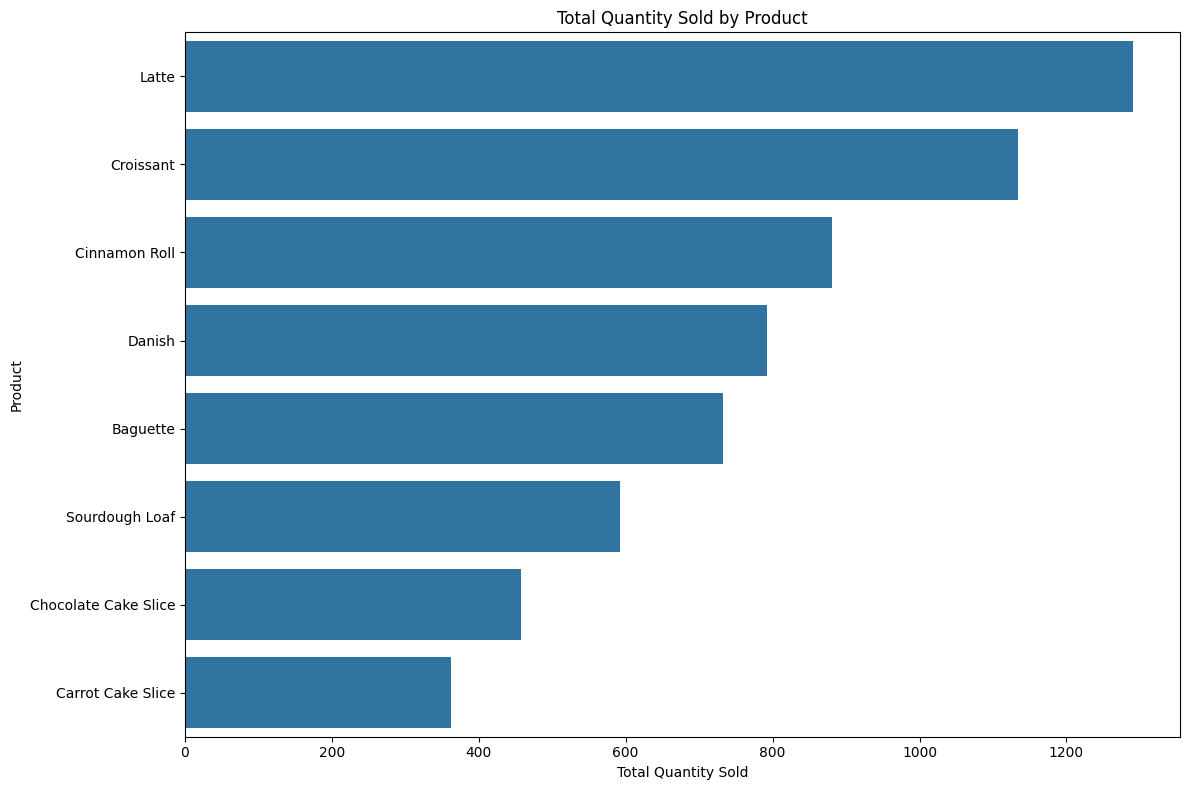

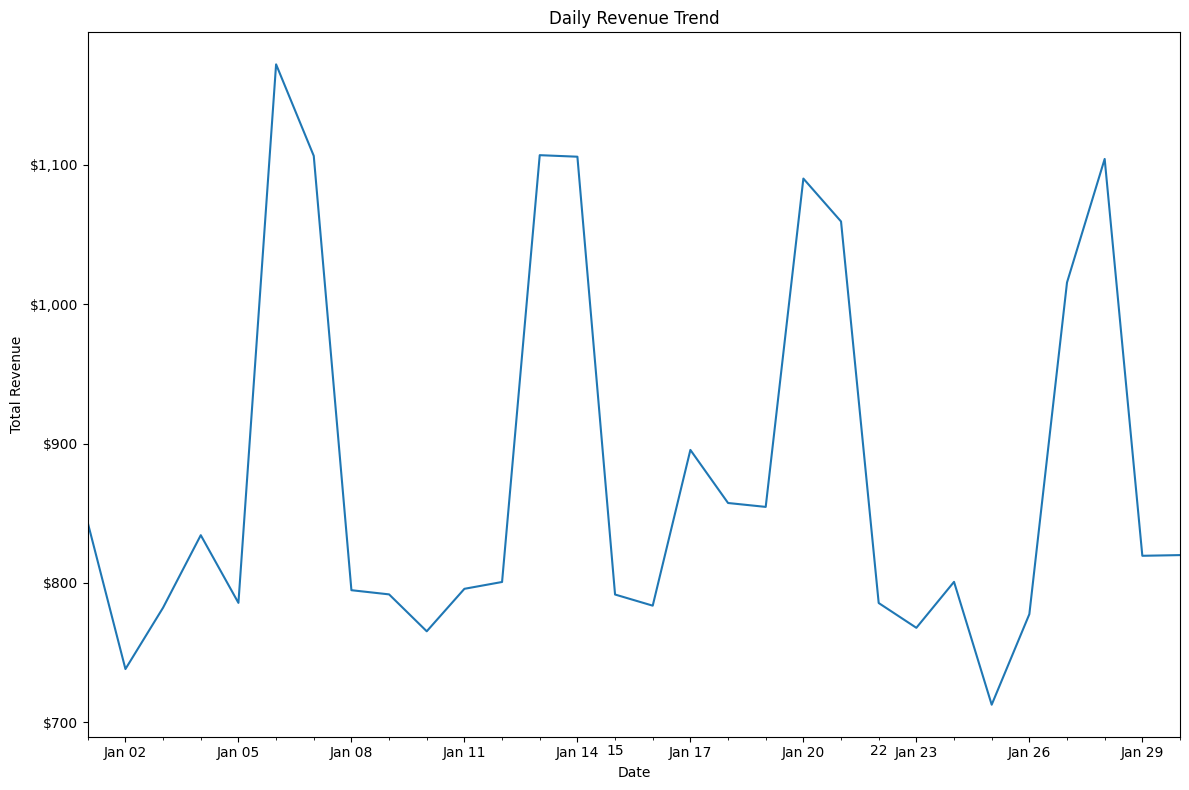

In [7]:
# Visualization
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Chart 1: total quantity sold by product (bar)
fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(x=sales_by_product.values, y=sales_by_product.index, ax=ax)
ax.set_title('Total Quantity Sold by Product')
ax.set_xlabel('Total Quantity Sold')
ax.set_ylabel('Product')
plt.tight_layout()
plt.show()

# Chart 2: daily revenue trend across the month (line)

fig, ax = plt.subplots(figsize=(12, 8))
df.groupby('date')['revenue'].sum().plot(kind='line', ax=ax)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.tick_params(axis='x')
ax.set_title('Daily Revenue Trend')
ax.set_xlabel('Date')
ax.set_ylabel('Total Revenue')
plt.tight_layout()
plt.show()



---
# 💼 Business Insights
*What did I discover?*

- Latte sold the most units (**1,290**) and Carrot Cake Slice the least (**363**).
  (Latte가 1,290개로 가장 많이, Carrot Cake Slice가 363개로 가장 적게 팔림)
- Pastries brought in the most revenue (**$9,567.10**) and Cakes the least (**$4,938.80**).
  (매출은 Pastries $9,567.10이 가장 높고 Cakes $4,938.80이 가장 낮음)
- A weekend day averages **$1,095.14**, **$295.29** above a weekday (**$799.85**).
  (주말 하루 평균 $1,095.14, 평일 $799.85보다 $295.29 높음)


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Keep Latte and Croissant well stocked. They are the two highest unit sellers, **1,290** and **1,134**.
   (Latte와 Croissant 재고를 넉넉히 두기. 판매량 1, 2위, 1,290개와 1,134개)
2. Treat Pastries as the revenue driver. That category is **$4,628.30** above Cakes.
   (Pastries를 매출의 중심으로 보기. Cakes보다 $4,628.30 높음)
3. Staff and bake for a higher weekend day. Weekend daily revenue is **$295.29** above a weekday.
   (주말 하루 매출이 평일보다 $295.29 높으니, 주말 인력과 생산을 더 두기)


---
# ❌ Mistakes
*What mistakes did I make today?*

- I averaged `revenue` on each product row. That is one product's sales, not the store's sales for the day.
  (상품 행의 revenue를 바로 평균냄. 그건 상품 하나의 매출이지, 그날 가게 매출이 아님)
- Chart 1 had the axis names swapped: quantity was on x and the product name was on y.
  (Chart 1 축 이름이 바뀌어 있었음. x가 수량, y가 상품 이름)
- I first grouped Chart 2 by weekday name. The question asks for each date in the month.
  (Chart 2를 요일 이름으로 묶으려 했음. 질문은 한 달의 날짜별 매출)


---
# ✅ What I Learned
*Today's biggest lesson*

- `groupby` plus `sum` and `sort_values(ascending=False)` ranks products and categories.
  (groupby에 sum을 하고 sort_values(ascending=False)를 하면 상품·카테고리 순위가 나옴)
- Average daily revenue needs a daily total first: `groupby('date')['revenue'].sum()`, then split weekdays and weekends.
  (하루 평균 매출은 먼저 groupby('date')로 그날 합계를 만든 다음 평일·주말을 나눔)
- A datetime axis can show `Jan 1` with `mdates.DateFormatter('%b %d')` and a tick every 3 days.
  (날짜 축은 mdates.DateFormatter('%b %d')와 3일 간격 눈금으로 Jan 1처럼 표시할 수 있음)


---
# 🧠 Reflection

**What was difficult?**
Telling a product-row average apart from an average of daily totals.
(상품 행 평균과 하루 합계의 평균을 구분하는 것)

**Why?**
Each date has 8 product rows, so `mean()` on those rows divides the day's sales by 8.
(하루가 상품 8행이라, 그 행에 mean()을 하면 그날 매출을 8로 나눈 값이 됨)

**How did I solve it?**
Summed revenue by `date` first, then grouped those 30 daily totals by weekend.
(revenue를 date로 먼저 합친 뒤, 그 30개 하루 매출을 주말 여부로 나눔)

**What would I do differently next time?**
Check whether the question says "per day" before averaging a table that has several rows per day.
(하루에 행이 여러 개면, 평균을 내기 전에 질문이 "하루당"인지 먼저 확인하기)


---
# ⭐ Self Evaluation

**Understanding**
★★★★★★★☆☆☆
Product totals, category totals, and the daily-then-weekend average are clear.
(상품 합계, 카테고리 합계, 하루 합계 다음 주말 평균은 이해함)

**Confidence**
★★★★★★☆☆☆☆

**Difficulty**
★★★★★★☆☆☆☆
The daily total step in Question 3 was the new part.
(Question 3에서 하루 합계를 먼저 만드는 단계가 새로웠음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 30 — NumPy basics (Round 3/5)
  (NumPy 기초 복습)
